<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

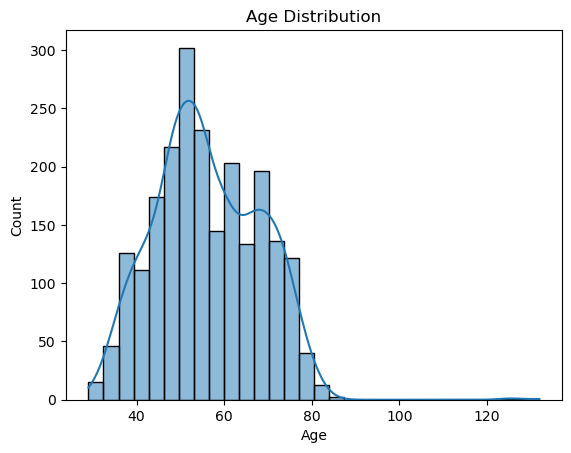

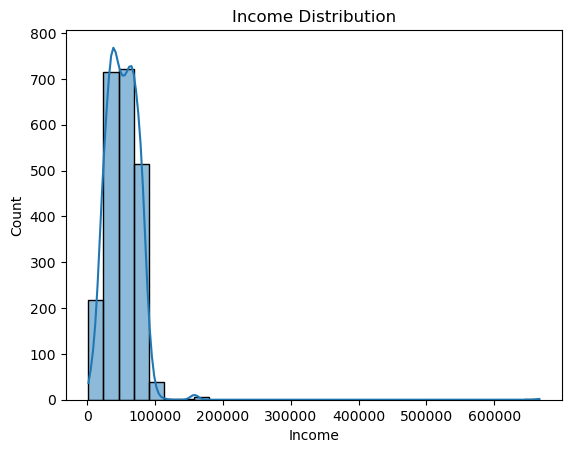

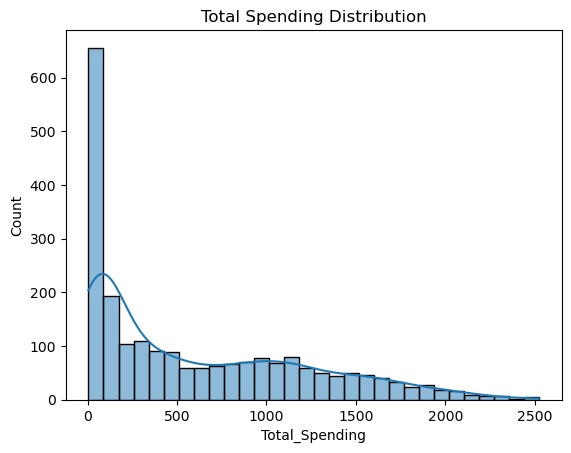

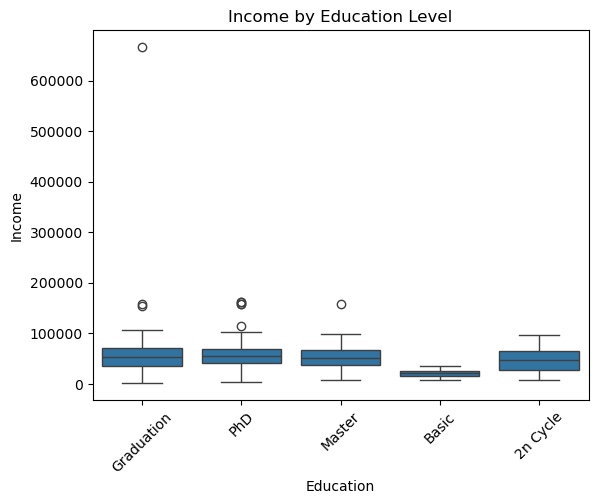

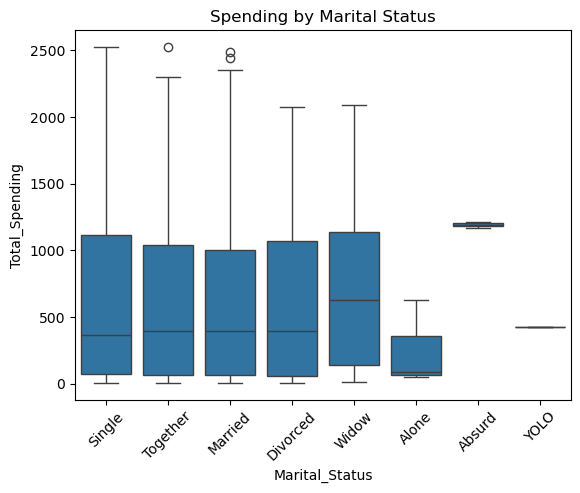

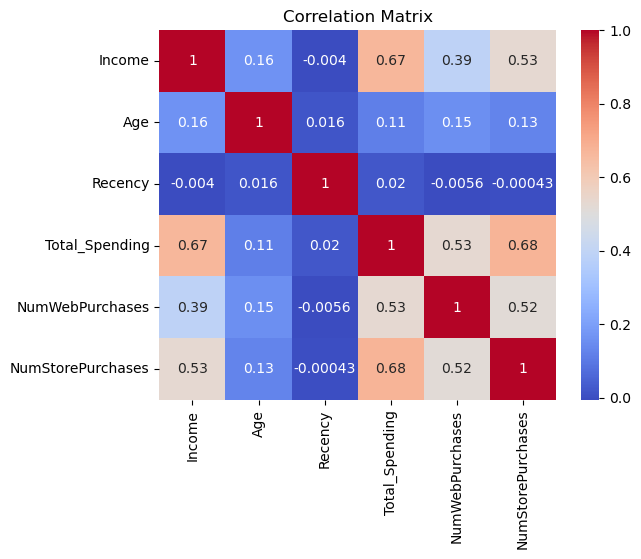

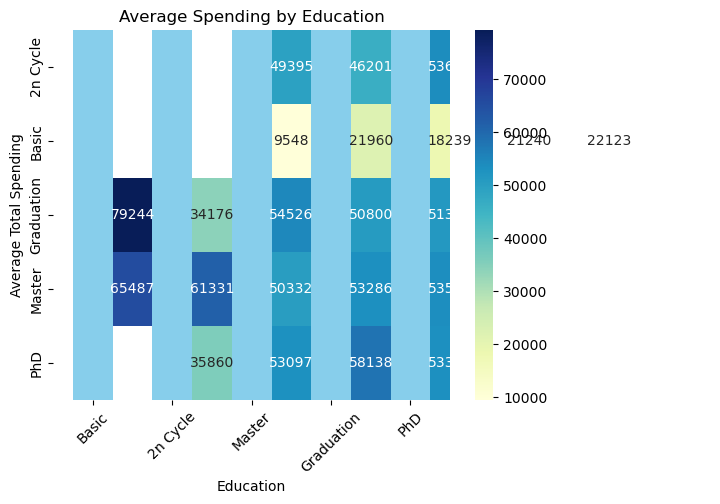

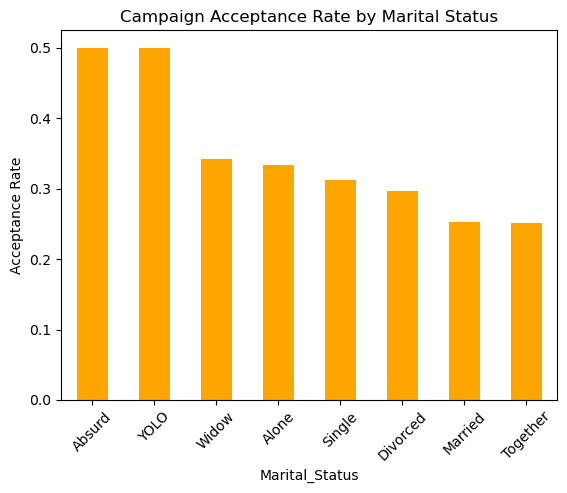

C:\Users\Hp\AppData\Local\Temp\ipykernel_47144\1290458691.py:141: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group3 = data.groupby("AgeGroup")["Income"].mean()


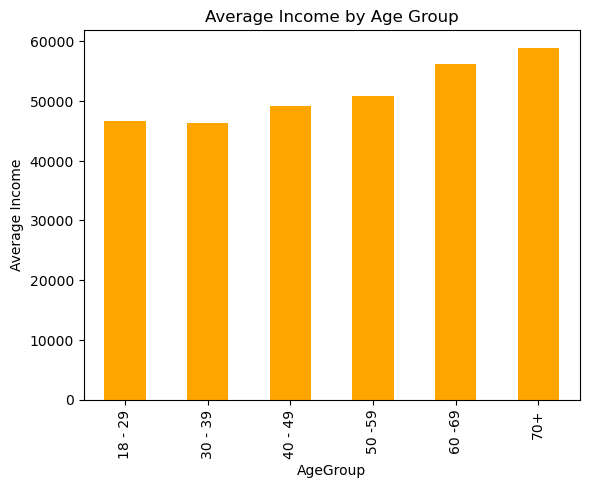

Silhouette scores for k = 2 to 9:



C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


K = 2  -> Silhouette Score = 0.3215


C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


K = 3  -> Silhouette Score = 0.2077


C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


... (7 outputs left out)

C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


K = 8  -> Silhouette Score = 0.1833


C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


K = 9  -> Silhouette Score = 0.1824

✅ Best K = 2
✅ Best Silhouette Score = 0.3215123349066069


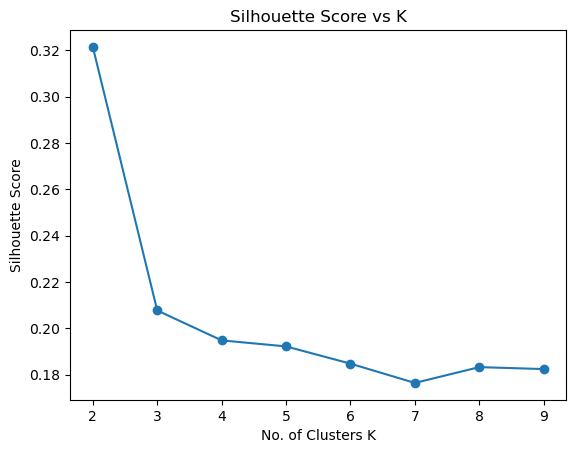

C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


Cluster
0    1158
1    1058
Name: count, dtype: int64

In [1]:
# ---------------------------------------------------------
# IMPORTS
# ---------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------
data=pd.read_csv("C:\\Users\\Hp\\Desktop\\pds project\\customer_segmentation.csv")
data.head()
data.columns
data.shape
data.info()

# ---------------------------------------------------------
# HANDLE MISSING VALUES
# ---------------------------------------------------------
data.isnull().sum()
data.dropna(inplace=True)
data.isnull().sum()
data.describe()

# ---------------------------------------------------------
# FEATURE ENGINEERING (Age, Total Children, Spending, Duration)
# ---------------------------------------------------------
data["Education"].value_counts()
data["Dt_customer"]=pd.to_datetime(data["Dt_Customer"],dayfirst = True)
data.info()

# Age
data["Age"] =2025 - data["Year_Birth"]

data.head()

# Total Children
data["Total_Children"] = data["Kidhome"] + data["Teenhome"]

data.columns

# Total Spending
spend_cols =['MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds']

data["Total_Spending"] = data[spend_cols].sum(axis=1)

# Customer Since (days)
data['Customer_Since'] =  (pd.Timestamp('today') - data['Dt_customer']).dt.days


# ---------------------------------------------------------
# EDA — DISTRIBUTIONS
# ---------------------------------------------------------
sns.histplot(data["Age"],bins=30,kde=True)
plt.title("Age Distribution")
plt.show()

sns.histplot(data["Income"],bins=30,kde=True)
plt.title("Income Distribution")
plt.show()

sns.histplot(data["Total_Spending"],bins=30,kde=True)
plt.title("Total Spending Distribution")
plt.show()


# ---------------------------------------------------------
# EDA — BOX PLOTS
# ---------------------------------------------------------
sns.boxplot(x="Education" , y = "Income" , data = data)
plt.xticks(rotation = 45)
plt.title("Income by Education Level")
plt.show()

sns.boxplot(x="Marital_Status" , y = "Total_Spending" , data = data)
plt.xticks(rotation = 45)
plt.title("Spending by Marital Status")
plt.show()


# ---------------------------------------------------------
# EDA — CORRELATION MATRIX
# ---------------------------------------------------------
corr = data[['Income','Age','Recency','Total_Spending',
             'NumWebPurchases','NumStorePurchases']].corr()

sns.heatmap(corr, annot = True, cmap ="coolwarm")
plt.title("Correlation Matrix")
plt.show()


# ---------------------------------------------------------
# EDA — PIVOT TABLE
# ---------------------------------------------------------
pivot_income = data.pivot_table(values = "Income", index = "Education",
                                columns = "Marital_Status",aggfunc = "mean")

sns.heatmap(pivot_income, annot = True, fmt = ".0f", cmap = "YlGnBu")
plt.title("Average Income by Education and Marital Status")


# ---------------------------------------------------------
# GROUP 1 — Avg Spending by Education
# ---------------------------------------------------------
group1 = data.groupby("Education")["Total_Spending"].mean().sort_values(ascending = True)

group1.plot(kind="bar",color= "skyblue")
plt.title("Average Spending by Education")
plt.ylabel("Average Total Spending")
plt.xticks(rotation = 45)
plt.show()


# ---------------------------------------------------------
# GROUP 2 — Campaign Acceptance Rate by Marital Status
# ---------------------------------------------------------
data["AcceptedAny"]=data[["AcceptedCmp1","AcceptedCmp2","AcceptedCmp3",
                          "AcceptedCmp4","AcceptedCmp5","Response"]].sum(axis=1)
data["AcceptedAny"]=data["AcceptedAny"].apply(lambda x:1 if x > 0 else 0)

group2 = data.groupby("Marital_Status")["AcceptedAny"].mean().sort_values(ascending = False)

group2.plot(kind="bar",color= "orange")
plt.title("Campaign Acceptance Rate by Marital Status")
plt.ylabel("Acceptance Rate")
plt.xticks(rotation = 45)
plt.show()


# ---------------------------------------------------------
# GROUP 3 — Avg Income by Age Group
# ---------------------------------------------------------
bins = [18,30,40,50,60,70,90]
labels = ["18 - 29", "30 - 39","40 - 49","50 -59","60 -69","70+"]

data["AgeGroup"]=pd.cut(data["Age"], bins = bins, labels =labels)

group3 = data.groupby("AgeGroup")["Income"].mean()

group3.plot(kind="bar",color= "orange")
plt.title("Average Income by Age Group")
plt.ylabel("Average Income")
plt.show()


# ---------------------------------------------------------
# PREPARE FEATURES FOR CLUSTERING
# ---------------------------------------------------------
data.head()
data.columns

features = ["Age", "Income" ,"Total_Spending",
            "NumWebPurchases","NumStorePurchases",
            "NumWebVisitsMonth","Recency"]

X=data[features].copy()


# ---------------------------------------------------------
# SCALING
# ---------------------------------------------------------
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# ---------------------------------------------------------
# ✅ RESEARCH PAPER 1 — SILHOUETTE ANALYSIS (replaces elbow)
# ---------------------------------------------------------
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sil_scores = {}

print("Silhouette scores for k = 2 to 9:\n")
for k in range(2,10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores[k] = score
    print(f"K = {k}  -> Silhouette Score = {score:.4f}")

best_k = max(sil_scores, key=sil_scores.get)
print("\n✅ Best K =", best_k)
print("✅ Best Silhouette Score =", sil_scores[best_k])

plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o')
plt.title("Silhouette Score vs K")
plt.xlabel("No. of Clusters K")
plt.ylabel("Silhouette Score")
plt.show()


# ---------------------------------------------------------
# FINAL K-MEANS USING BEST K
# ---------------------------------------------------------
kmeans = KMeans(n_clusters=best_k, random_state=42)
data["Cluster"] = kmeans.fit_predict(X_scaled)

cluster_summary = data.groupby("Cluster")[features].mean()
cluster_summary

data["Cluster"].value_counts()


✅ PCA Shape: (2216, 6)
✅ Explained Variance Ratio: [0.43281928 0.1441598  0.14111915 0.1353327  0.06268449 0.04497116]
✅ Total Variance Explained: 0.9610865779250937

Silhouette scores for PCA-KMeans (k = 2–9):



C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


K = 2  -> Silhouette Score (PCA) = 0.3300


C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


K = 3  -> Silhouette Score (PCA) = 0.2012


C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


... (7 outputs left out)

C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


K = 8  -> Silhouette Score (PCA) = 0.1796


C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


K = 9  -> Silhouette Score (PCA) = 0.1779

✅ Best K after PCA = 2
✅ Best Silhouette Score (PCA-KMeans) = 0.33001673310758856

---------------- COMPARISON ----------------
Normal KMeans Best Silhouette  : 0.3215
PCA-KMeans Best Silhouette     : 0.3300

✅ PCA-KMeans performed BETTER than normal KMeans.


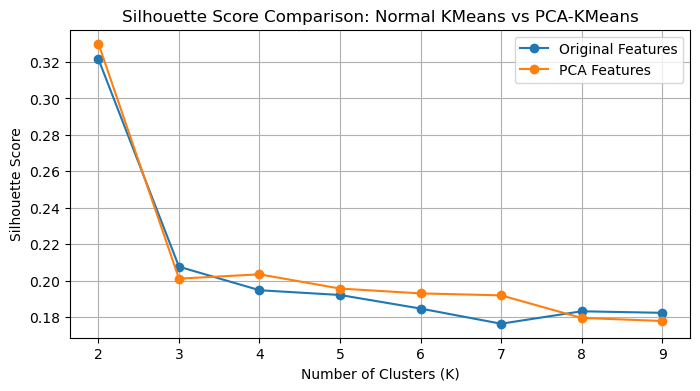

C:\Users\Hp\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(



 PCA-KMeans Cluster Summary:
                   Age        Income  Total_Spending  NumWebPurchases  \
PCA_Cluster                                                             
0            54.023417  35630.888118      135.464007         2.500434   
1            58.518344  70270.456256     1118.616181         5.804327   

             NumStorePurchases  NumWebVisitsMonth    Recency  
PCA_Cluster                                                   
0                     3.432784           6.546401  48.797918  
1                     8.369708           3.987770  49.245532  

Cluster Counts (PCA-KMeans):
PCA_Cluster
0    1153
1    1063
Name: count, dtype: int64


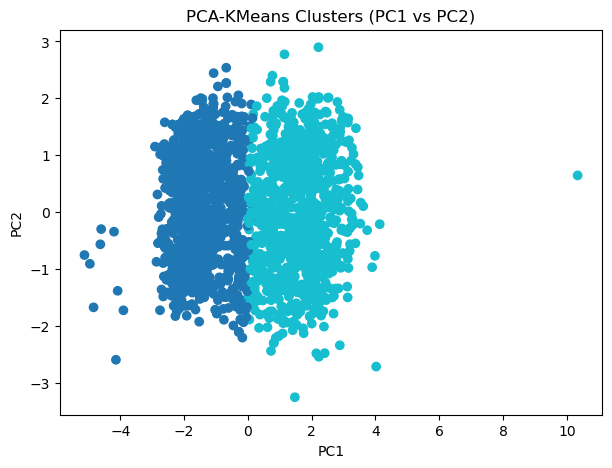

In [6]:
# ---------------------------------------------------------
# ✅ RESEARCH PAPER 2 — PCA + K-MEANS CLUSTERING
# ---------------------------------------------------------

from sklearn.decomposition import PCA

# ---------------------------------------------------------
# PCA (Keep components explaining 95% variance)
# ---------------------------------------------------------
pca = PCA(n_components=0.95, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("✅ PCA Shape:", X_pca.shape)
print("✅ Explained Variance Ratio:", pca.explained_variance_ratio_)
print("✅ Total Variance Explained:", pca.explained_variance_ratio_.sum())

# ---------------------------------------------------------
# Silhouette Score for PCA-Transformed Data
# ---------------------------------------------------------
sil_scores_pca = {}

print("\nSilhouette scores for PCA-KMeans (k = 2–9):\n")
for k in range(2,10):
    model_pca = KMeans(n_clusters=k, random_state=42)
    labels_pca = model_pca.fit_predict(X_pca)
    score_pca = silhouette_score(X_pca, labels_pca)
    sil_scores_pca[k] = score_pca
    print(f"K = {k}  -> Silhouette Score (PCA) = {score_pca:.4f}")

best_k_pca = max(sil_scores_pca, key=sil_scores_pca.get)

print("\n✅ Best K after PCA =", best_k_pca)
print("✅ Best Silhouette Score (PCA-KMeans) =", sil_scores_pca[best_k_pca])

# ---------------------------------------------------------
# Compare Normal vs PCA Silhouette
# ---------------------------------------------------------
print("\n---------------- COMPARISON ----------------")
print(f"Normal KMeans Best Silhouette  : {sil_scores[best_k]:.4f}")
print(f"PCA-KMeans Best Silhouette     : {sil_scores_pca[best_k_pca]:.4f}")

if sil_scores_pca[best_k_pca] > sil_scores[best_k]:
    print("\n✅ PCA-KMeans performed BETTER than normal KMeans.")
else:
    print("\n✅ Normal KMeans performed better OR equal.")

# ---------------------------------------------------------
# PLOT — Silhouette Scores (Normal vs PCA)
# ---------------------------------------------------------

plt.figure(figsize=(8,4))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o', label="Original Features")
plt.plot(list(sil_scores_pca.keys()), list(sil_scores_pca.values()), marker='o', label="PCA Features")
plt.title("Silhouette Score Comparison: Normal KMeans vs PCA-KMeans")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.legend()
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# FINAL PCA-KMEANS USING THE BEST K
# ---------------------------------------------------------
pca_kmeans = KMeans(n_clusters=best_k_pca, random_state=42)
data["PCA_Cluster"] = pca_kmeans.fit_predict(X_pca)

# ---------------------------------------------------------
# CLUSTER SUMMARY FOR PCA-KMEANS
# ---------------------------------------------------------
pca_cluster_summary = data.groupby("PCA_Cluster")[features].mean()
print("\n PCA-KMeans Cluster Summary:")
print(pca_cluster_summary)

print("\nCluster Counts (PCA-KMeans):")
print(data["PCA_Cluster"].value_counts())

# ---------------------------------------------------------
# OPTIONAL: VISUALIZE CLUSTERS (PC1 vs PC2)
# ---------------------------------------------------------
if X_pca.shape[1] >= 2:
    plt.figure(figsize=(7,5))
    plt.scatter(X_pca[:,0], X_pca[:,1], c=data["PCA_Cluster"], cmap="tab10")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("PCA-KMeans Clusters (PC1 vs PC2)")
    plt.show()


In [5]:
# ✅ Cluster Summary for Simple KMeans (Original Features)
print("\nSimple KMeans Cluster Summary:\n")
cluster_summary_simple = data.groupby("Cluster")[features].mean()
print(cluster_summary_simple)

# ✅ Cluster Counts
print("\n Simple KMeans Cluster Counts:")
print(data["Cluster"].value_counts())



Simple KMeans Cluster Summary:

               Age        Income  Total_Spending  NumWebPurchases  \
Cluster                                                             
0        54.050950  35726.877375      136.246978         2.506908   
1        58.509452  70329.097353     1122.405482         5.812854   

         NumStorePurchases  NumWebVisitsMonth    Recency  
Cluster                                                   
0                 3.443869           6.536269  48.721071  
1                 8.380907           3.986767  49.331758  

 Simple KMeans Cluster Counts:
Cluster
0    1158
1    1058
Name: count, dtype: int64


NameError: name 'data' is not defined